# 05 - Credit Scoring and Risk Tiers
**Topic:** Classification  |  **Reference:** "Credit Scoring and Segmentation using Python" (amanxai.com, Jul 2023)

**Question.** Can we turn an applicant's profile into a single *credit score* that ranks people by the chance they will not repay, and then cut the score into risk tiers a lender can act on?

**Reference method:** a 1,000-row synthetic table with **no repayment outcome**; the score is a hand-weighted formula over a few columns, then k-means groups the scores. Nothing in it can tell whether the score predicts defaults.
**What I do differently:** use the real German Credit data (1,000 loans, **with** a good/bad outcome), build a classic **scorecard** (weight-of-evidence + logistic regression, points scaled like a bureau score), validate it with the industry metrics (AUC, Gini, KS), compare with a more flexible model, and check that the tiers actually separate bad rates.

## 1. Libraries and data

In [1]:
import warnings, os, json, joblib
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.datasets import fetch_openml
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, cross_val_predict, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, roc_curve
sns.set_theme(style="whitegrid", context="notebook")
os.makedirs("model", exist_ok=True)
cache = "../_data/german_credit.csv"
if os.path.exists(cache): raw = pd.read_csv(cache)
else:
    raw = fetch_openml(data_id=31, as_frame=True, parser="auto").frame; raw.to_csv(cache, index=False)
df = raw.copy()
df["bad"] = (df["class"] == "bad").astype(int)           # 1 = did not repay (the event we score)
df = df.drop(columns="class")
print(df.shape, "| bad rate: %.1f%%" % (df.bad.mean() * 100)); df.head(3).T

(1000, 21) | bad rate: 30.0%


,0,1,2
checking_status,<0,0<=X<200,no checking
duration,6,48,12
credit_history,critical/other existing credit,existing paid,critical/other existing credit
purpose,radio/tv,radio/tv,education
credit_amount,1169,5951,2096
savings_status,no known savings,<100,<100
employment,>=7,1<=X<4,4<=X<7
installment_commitment,4,2,2
personal_status,male single,female div/dep/mar,male single
other_parties,none,none,none


**Columns (20 inputs).** Checking-account status, loan duration (months) and amount, credit history, purpose, savings, employment length, instalment rate, personal status, other debtors, residence length, property, age, other instalment plans, housing, existing credits, job, dependents, telephone, foreign worker. The target `bad` = 1 means the loan went bad (30% of the 1,000).

## 2. Look at the data first

numeric: ['duration', 'credit_amount', 'installment_commitment', 'residence_since', 'age', 'existing_credits', 'num_dependents']
categorical: 13 columns
missing: 0


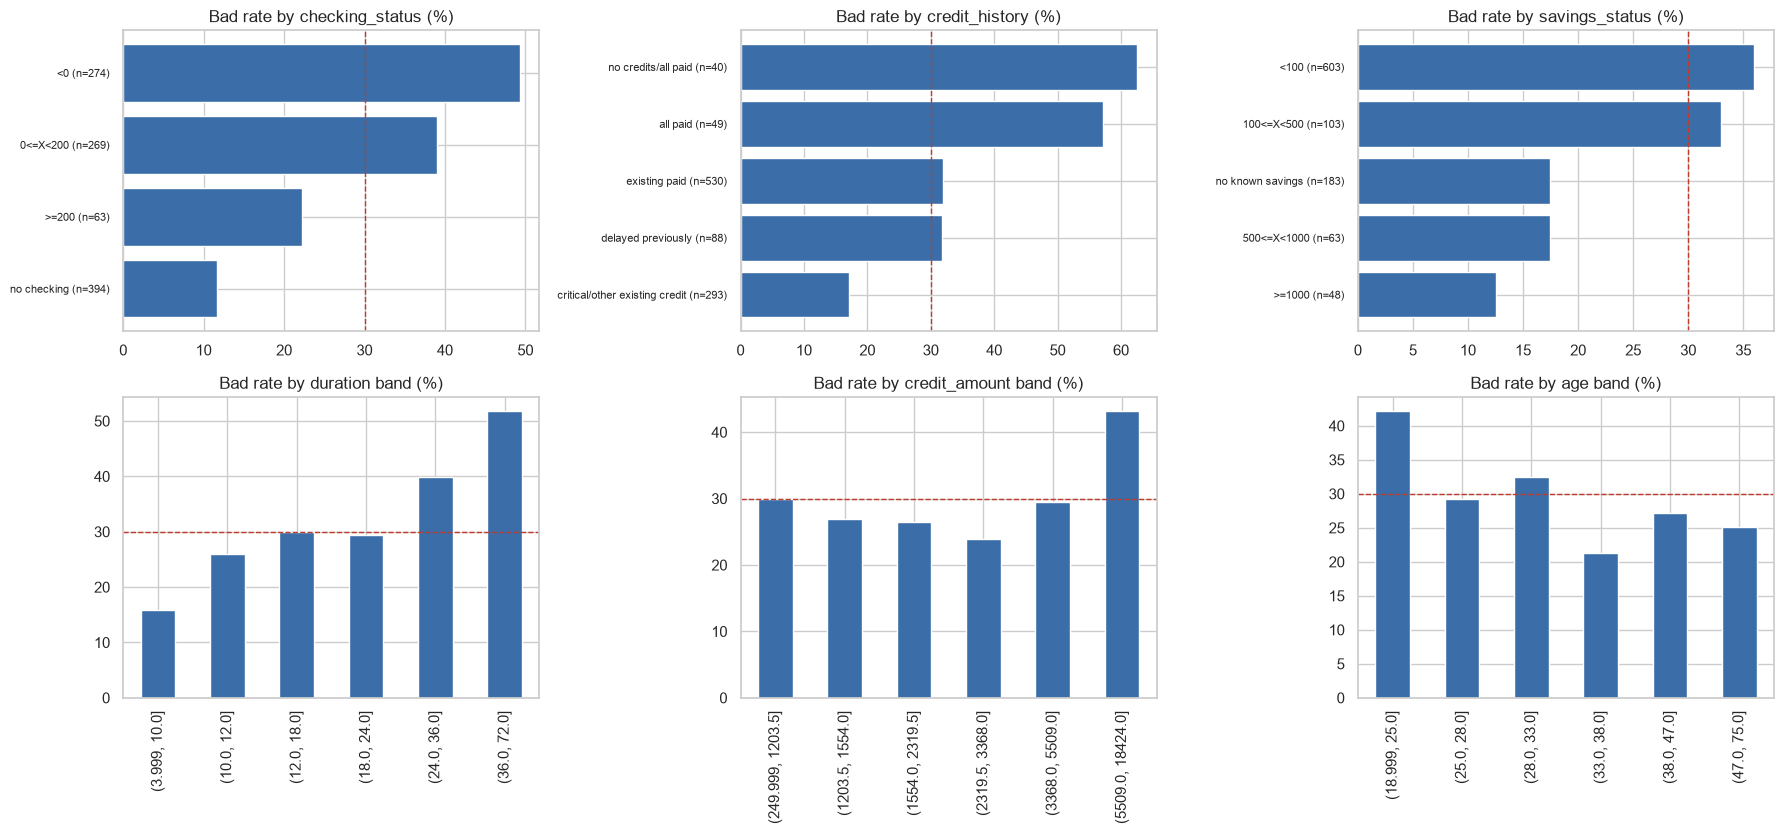

In [2]:
num = [c for c in df.columns if df[c].dtype.kind in "if" and c != "bad"]
cat = [c for c in df.columns if c not in num + ["bad"]]
print("numeric:", num); print("categorical:", len(cat), "columns"); print("missing:", int(df.isna().sum().sum()))
fig, ax = plt.subplots(2, 3, figsize=(18, 8.5))
for a, c in zip(ax.ravel()[:3], ["checking_status", "credit_history", "savings_status"]):
    g = df.groupby(c, observed=True)["bad"].agg(["mean", "size"]).sort_values("mean")
    a.barh([f"{k} (n={n})" for k, n in zip(g.index.astype(str), g["size"])], g["mean"] * 100, color="#3b6ea8"); a.axvline(df.bad.mean() * 100, color="#c0392b", ls="--", lw=1)
    a.set_title(f"Bad rate by {c} (%)"); a.tick_params(axis="y", labelsize=8)
for a, c in zip(ax.ravel()[3:], ["duration", "credit_amount", "age"]):
    df.assign(b=pd.qcut(df[c], 6, duplicates="drop")).groupby("b", observed=True)["bad"].mean().mul(100).plot.bar(ax=a, color="#3b6ea8"); a.axhline(df.bad.mean() * 100, color="#c0392b", ls="--", lw=1); a.set_title(f"Bad rate by {c} band (%)"); a.set_xlabel("")
plt.tight_layout(); plt.show()

**Reading it.**
* **Checking account status is the strongest signal:** bad rate 12% for "no checking account" (394 loans), 22% for balance >= 200, 39% for balance 0-200 and **49% for overdrawn accounts** (<0; 274 loans), against 30% overall.
* Savings: 36% bad for "<100" savings (603 loans) vs 12% for savings >= 1000 (only 48 loans).
* Longer loans are riskier: bad rate rises from 16% (up to 10 months) to 52% (over 36 months). Younger applicants (19-25) show 42% bad vs 21-32% in other age bands.
* Some categories are tiny (e.g. "retraining" has 9 loans), so their rates are unstable. All of this is association in one 1990s German sample, not cause.

## 3. A scorecard, step by step
**Weight of evidence (WoE).** Cut each variable into groups (numbers into quantile bins). For a group, `WoE = ln( share of all good loans in the group / share of all bad loans in the group )`: positive = safer than average, negative = riskier. **Information value (IV)** sums this over groups and ranks how useful a variable is. A logistic regression on the WoE values then gives a model whose every coefficient is easy to read, and **points** are the scaled log-odds.

To keep validation honest, the WoE tables are learned **inside each cross-validation fold** (a custom transformer), never on the validation rows.

In [3]:
class WoE(BaseEstimator, TransformerMixin):
    def __init__(self, num_cols, cat_cols, n_bins=5, smooth=0.5):
        self.num_cols, self.cat_cols, self.n_bins, self.smooth = num_cols, cat_cols, n_bins, smooth
    def _group(self, s, c):
        if c in self.num_cols: return pd.cut(s, self.edges_[c], include_lowest=True).astype(str)
        return s.astype(str)
    def fit(self, X, y):
        y = pd.Series(np.asarray(y), index=X.index)
        self.edges_, self.table_, self.iv_ = {}, {}, {}
        for c in self.num_cols:
            q = np.unique(np.quantile(X[c], np.linspace(0, 1, self.n_bins + 1))); q[0], q[-1] = -np.inf, np.inf; self.edges_[c] = q
        G, B = (y == 0).sum(), (y == 1).sum()
        for c in self.num_cols + self.cat_cols:
            g = self._group(X[c], c)
            t = pd.crosstab(g, y).reindex(columns=[0, 1], fill_value=0) + self.smooth
            woe = np.log((t[0] / (G + self.smooth * len(t))) / (t[1] / (B + self.smooth * len(t))))
            self.table_[c] = woe.to_dict(); self.iv_[c] = float(((t[0] / t[0].sum() - t[1] / t[1].sum()) * woe).sum())
        return self
    def transform(self, X):
        return pd.DataFrame({c: self._group(X[c], c).map(self.table_[c]).fillna(0.0).to_numpy() for c in self.num_cols + self.cat_cols}, index=X.index)
X, y = df.drop(columns="bad"), df.bad
w_all = WoE(num, cat).fit(X, y)
iv = pd.Series(w_all.iv_).sort_values(ascending=False)
print(iv.round(3).to_string())

checking_status           0.659
credit_history            0.291
duration                  0.213
savings_status            0.188
purpose                   0.164
property_magnitude        0.112
credit_amount             0.092
employment                0.086
housing                   0.084
age                       0.067
other_payment_plans       0.058
personal_status           0.045
foreign_worker            0.039
other_parties             0.031
installment_commitment    0.025
job                       0.009
own_telephone             0.006
existing_credits          0.003
residence_since           0.000
num_dependents            0.000


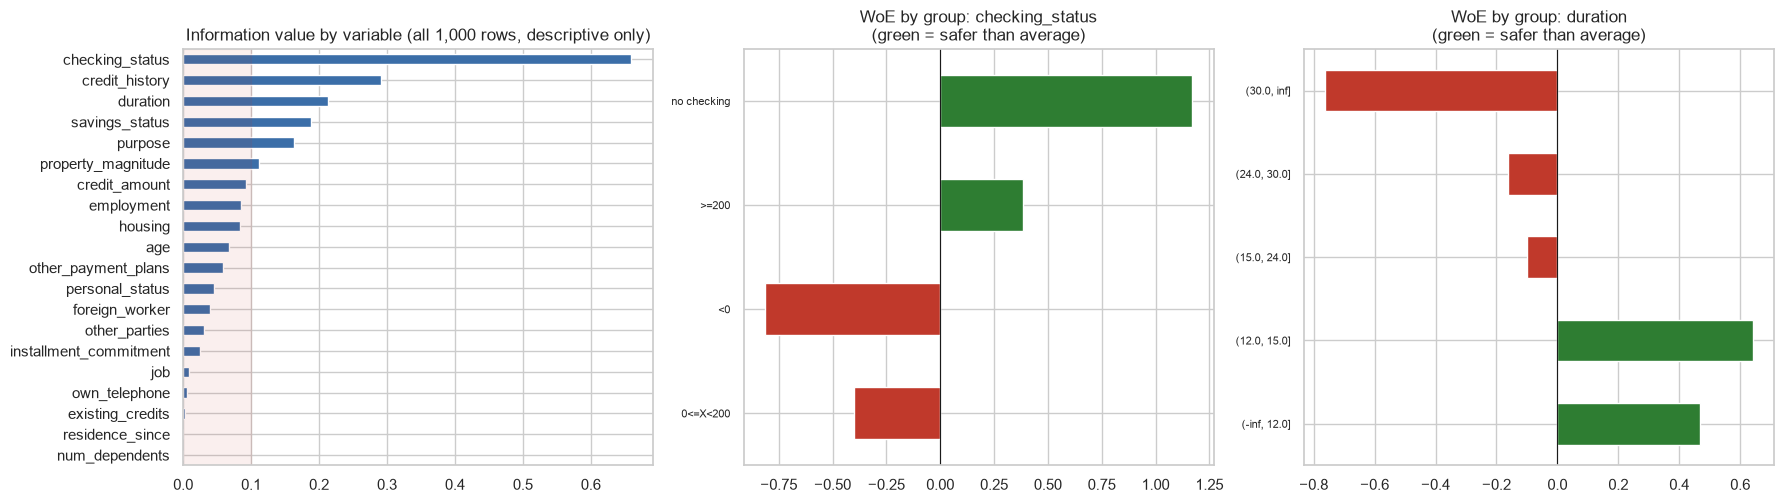

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5.2))
iv.sort_values().plot.barh(ax=ax[0], color="#3b6ea8"); ax[0].set_title("Information value by variable (all 1,000 rows, descriptive only)")
for v, lo, hi in [(0.02, 0, .1)]: ax[0].axvspan(lo, hi, color="#c0392b", alpha=.08)
for a, c in zip(ax[1:], ["checking_status", "duration"]):
    t = pd.Series(w_all.table_[c]); t.plot.barh(ax=a, color=np.where(t > 0, "#2e7d32", "#c0392b")); a.set_title(f"WoE by group: {c}\n(green = safer than average)"); a.axvline(0, color="k", lw=.8); a.tick_params(axis="y", labelsize=8)
plt.tight_layout(); plt.show()

**Reading it.** By information value (rule of thumb: < 0.02 useless, 0.1-0.3 medium, 0.3-0.5 strong, > 0.5 unusually strong), `checking_status` (0.66) is far ahead, then `credit_history` (0.29), `duration` (0.21), `savings_status` (0.19) and `purpose` (0.16). `residence_since`, `num_dependents`, `existing_credits` and `own_telephone` carry almost nothing. These IVs are computed on all 1,000 rows, so they describe the data; they are not a validated ranking. The WoE bars (right) show the direction: "no checking" and large balances are safer than average, "<0" is riskier, and the longest loans (> 30 months) are the riskiest duration group.

## 4. Models, scored with repeated 5-fold CV (5 repeats)
* **Scorecard**: WoE of all 20 variables -> logistic regression (L2).
* **Scorecard, top 10 by IV**: fewer variables, fitted in each fold.
* **Logistic regression on one-hot dummies** (no WoE) and **gradient boosting** as flexible comparisons.
Metrics: **AUC**, **Gini** (= 2*AUC - 1) and **KS** (largest gap between the cumulative good and bad score distributions) - the standard trio in credit risk.

In [5]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
class TopIV(BaseEstimator, TransformerMixin):
    def __init__(self, k=10): self.k = k
    def fit(self, X, y=None): return self
    def transform(self, X): return X
def ks_stat(y, s):
    fpr, tpr, _ = roc_curve(y, s); return float(np.max(tpr - fpr))
def make(kind):
    if kind == "scorecard": return make_pipeline(WoE(num, cat), LogisticRegression(C=0.3, max_iter=2000))
    if kind == "onehot": return make_pipeline(ColumnTransformer([("n", StandardScaler(), num), ("c", OneHotEncoder(handle_unknown="ignore"), cat)]), LogisticRegression(C=0.3, max_iter=3000))
    if kind == "gbm":
        from sklearn.preprocessing import OrdinalEncoder
        return make_pipeline(ColumnTransformer([("c", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), cat)], remainder="passthrough"),
                             HistGradientBoostingClassifier(learning_rate=.04, max_iter=150, max_depth=3, min_samples_leaf=20, l2_regularization=3.0, random_state=0))
# scorecard with top-10 variables: choose by IV inside the fold
class Top10Score(BaseEstimator):
    def __init__(self, k=10): self.k = k
    def fit(self, X, y):
        self.w_ = WoE(num, cat).fit(X, y); self.keep_ = list(pd.Series(self.w_.iv_).sort_values(ascending=False).index[: self.k])
        self.lr_ = LogisticRegression(C=0.3, max_iter=2000).fit(self.w_.transform(X)[self.keep_], y); self.classes_ = np.array([0, 1]); return self
    def predict_proba(self, X): return self.lr_.predict_proba(self.w_.transform(X)[self.keep_])
    def get_params(self, deep=True): return {"k": self.k}
    def set_params(self, **p): self.k = p.get("k", self.k); return self
def oof_scores(model_factory, seeds=5):
    out = []
    for s in range(seeds):
        p = np.zeros(len(y))
        for tr, te in StratifiedKFold(5, shuffle=True, random_state=s).split(X, y):
            m = model_factory().fit(X.iloc[tr], y.iloc[tr]); p[te] = m.predict_proba(X.iloc[te])[:, 1]
        out.append(p)
    return out
factories = {"scorecard (WoE + logistic, 20 vars)": lambda: make("scorecard"), "scorecard, top 10 by IV": lambda: Top10Score(10),
             "logistic on dummies": lambda: make("onehot"), "gradient boosting": lambda: make("gbm")}
oof, rows = {}, []
for name, f in factories.items():
    ps = oof_scores(f); oof[name] = ps[0]
    aucs = [roc_auc_score(y, p) for p in ps]; kss = [ks_stat(y, p) for p in ps]
    rows.append([name, np.mean(aucs), np.std(aucs), 2 * np.mean(aucs) - 1, np.mean(kss)])
res = pd.DataFrame(rows, columns=["model", "AUC", "AUC_sd_over_repeats", "Gini", "KS"]).set_index("model")
print(res.round(3).to_string())

                                       AUC  AUC_sd_over_repeats   Gini     KS
model                                                                        
scorecard (WoE + logistic, 20 vars)  0.786                0.002  0.572  0.467
scorecard, top 10 by IV              0.776                0.003  0.553  0.455
logistic on dummies                  0.788                0.004  0.576  0.460
gradient boosting                    0.781                0.003  0.562  0.446


**Reading it (cross-validated, 5 repeats).**
* The four approaches are practically tied: AUC 0.776-0.788 (Gini 0.55-0.58, KS 0.45-0.47). The repeat-to-repeat spread (0.002-0.004) is much smaller than the real uncertainty on 1,000 rows, so I would not rank them.
* **The transparent scorecard (AUC 0.786) matches the more flexible gradient boosting (0.781)**: nothing is gained by giving up interpretability here.
* Using only the top 10 variables loses about 0.01 AUC, a small price for a shorter form.

## 5. From probability to points and risk tiers
Standard scaling: **600 points = odds of 30:1 good:bad, and every +30 points doubles the odds** (these are conventions, not properties of the data). The final scorecard is fitted on all rows; the *tiers* below are evaluated on the **out-of-fold** probabilities so they are not flattered by in-sample fitting.

                  applicants  bad_rate  score_min  score_max
E (highest risk)         200     0.635      361.0      452.0
D                        200     0.415      452.0      484.0
C                        200     0.265      484.0      519.0
B                        200     0.135      519.0      555.0
A (lowest risk)          200     0.050      555.0      669.0


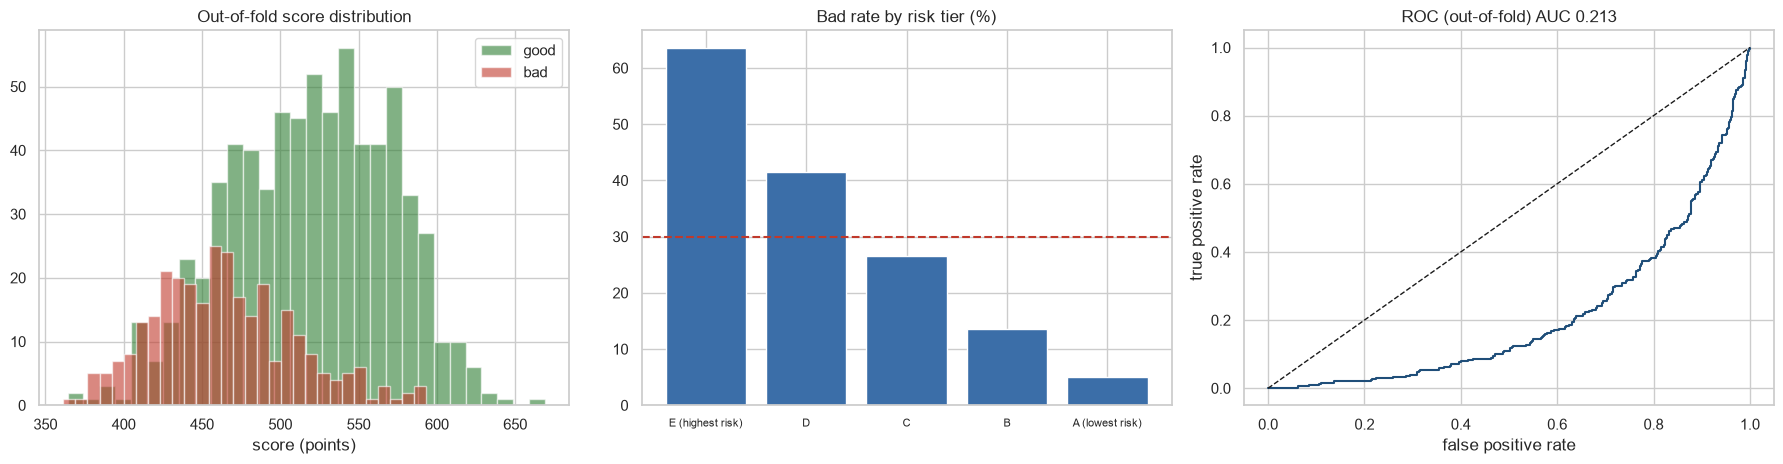

In [6]:
final = make("scorecard").fit(X, y)
BASE, ODDS0, PDO = 600, 30, 30
factor = PDO / np.log(2); offset = BASE - factor * np.log(ODDS0)
def to_points(p_bad):
    p = np.clip(p_bad, 1e-4, 1 - 1e-4); return offset + factor * np.log((1 - p) / p)
pts = pd.Series(to_points(oof["scorecard (WoE + logistic, 20 vars)"]), index=df.index)
tier = pd.qcut(pts, [0, .2, .4, .6, .8, 1], labels=["E (highest risk)", "D", "C", "B", "A (lowest risk)"])
tb = df.groupby(tier, observed=True).agg(applicants=("bad", "size"), bad_rate=("bad", "mean")); tb["score_min"] = pts.groupby(tier, observed=True).min().round(0); tb["score_max"] = pts.groupby(tier, observed=True).max().round(0)
print(tb.round(3).to_string())
fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))
for lab, col in [(0, "#2e7d32"), (1, "#c0392b")]: ax[0].hist(pts[y == lab], bins=30, alpha=.6, color=col, label=["good", "bad"][lab])
ax[0].set_title("Out-of-fold score distribution"); ax[0].set_xlabel("score (points)"); ax[0].legend()
ax[1].bar(tb.index.astype(str), tb.bad_rate * 100, color="#3b6ea8"); ax[1].axhline(df.bad.mean() * 100, color="#c0392b", ls="--"); ax[1].set_title("Bad rate by risk tier (%)"); ax[1].tick_params(axis="x", labelsize=8)
fpr, tpr, _ = roc_curve(y, pts); ax[2].plot(fpr, tpr, color="#1f4e79"); ax[2].plot([0, 1], [0, 1], "k--", lw=1); ax[2].set_title("ROC (out-of-fold) AUC %.3f" % roc_auc_score(y, pts)); ax[2].set_xlabel("false positive rate"); ax[2].set_ylabel("true positive rate")
plt.tight_layout(); plt.show()

**Reading it.** On out-of-fold scores, cutting into five equal groups gives a clean, monotone ladder: bad rate **63.5%** in the lowest-score tier E (score up to 452), 41.5%, 26.5%, 13.5%, and **5.0%** in tier A (score above 555). The gap between the best and worst tiers is about 13x. That is what a lender needs: the score *ranks* risk. It does not say a given applicant will default; tier E still contains 36% good loans. Tier cut-offs here are quintiles of this sample; a lender would pick cut-offs from its own appetite and costs.

## 6. What does each variable contribute? Points per group for the strongest variables
Reading the scorecard: points = factor x coefficient x WoE (plus a constant). Higher = safer.

In [7]:
lr = final[-1]; woe = final[0]
coef = pd.Series(lr.coef_[0], index=num + cat)
# coefficients are on the log-odds of BAD; safer groups (positive WoE) must therefore carry negative coefficient
top = iv.index[:6]
rows = []
for c in top:
    for g, w in woe.table_[c].items(): rows.append([c, g, round(float(-factor * coef[c] * w), 1)])
pointtab = pd.DataFrame(rows, columns=["variable", "group", "points"])
print("intercept points:", round(float(offset - factor * lr.intercept_[0]), 1), "(each variable's points are added to this)")
print(pointtab.to_string(index=False))

intercept points: 488.9 (each variable's points are added to this)
          variable                          group  points
   checking_status                       0<=X<200   -13.5
   checking_status                             <0   -27.5
   checking_status                          >=200    13.0
   checking_status                    no checking    39.5
    credit_history                       all paid   -32.3
    credit_history critical/other existing credit    21.0
    credit_history             delayed previously    -2.6
    credit_history                  existing paid    -2.4
    credit_history            no credits/all paid   -38.5
          duration                   (-inf, 12.0]    15.1
          duration                   (12.0, 15.0]    20.7
          duration                   (15.0, 24.0]    -3.2
          duration                   (24.0, 30.0]    -5.2
          duration                    (30.0, inf]   -24.6
    savings_status                     100<=X<500    -4.2
    s

**Reading it.**
* Directions are plausible for the strongest variables: no checking account +39.5 points, overdrawn account -27.5, savings >= 1000 +30.3, loans over 30 months -24.6, short loans +15 to +21.
* **Some patterns look counter-intuitive and I would question them before use:** credit history "all paid" scores -32 and "no credits / all paid" -38.5, while "critical / other existing credit" scores +21. This is a known quirk of this data set, probably a selection effect (customers with a critical record who still received a loan may have been screened more strictly), but the data cannot confirm why. Small groups (retraining: 9 loans, +33 points) get noisy points.
* `personal_status` (which in this data mixes sex and marital status), `age` and `foreign_worker` are inputs in the 20-variable version; in many jurisdictions lenders may not use some of these. I would remove them and re-check the AUC before any real use.

## 7. Save for the app

In [8]:
joblib.dump({"pipeline": final, "offset": float(offset), "factor": float(factor), "tier_edges": [float(x) for x in np.quantile(pts, [.2, .4, .6, .8])]}, "model/scorecard.joblib")
joblib.dump(make("gbm").fit(X, y), "model/credit_gbm.joblib")
meta = {"cat_values": {c: sorted(df[c].astype(str).unique().tolist()) for c in cat}, "ranges": {c: [float(df[c].min()), float(df[c].max())] for c in num},
        "defaults": {c: float(df[c].median()) for c in num}, "cat_default": {c: str(df[c].mode()[0]) for c in cat}, "bad_rate": float(df.bad.mean()),
        "tiers": tb.reset_index().astype(str).to_dict("records"), "cv": res.round(3).to_dict("index"), "iv": iv.round(3).to_dict(),
        "tier_edges": [float(x) for x in np.quantile(pts, [.2, .4, .6, .8])]}
json.dump(meta, open("model/meta.json", "w"), indent=1); print(os.listdir("model"))

['credit_gbm.joblib', 'meta.json', 'scorecard.joblib']


## 8. Summary: my approach vs the reference
| | Reference | This notebook |
|---|---|---|
| Data | 1,000 synthetic rows, no outcome | German Credit: 1,000 real loans, 30% bad |
| Score | hand-weighted formula | WoE + logistic regression, scaled to points (600 = 30:1 odds, +30 points = double the odds) |
| Segments | k-means on the score | risk tiers by score quintile |
| Validation | none possible (no outcome) | repeated CV: AUC 0.79, Gini 0.57, KS 0.47; bad rate 63.5% -> 5.0% across tiers |
| Interpretability | hidden in the formula | points per group, information value per variable |

**What I learned.** (1) A score without outcome data can be formatted nicely but cannot be validated; with outcomes, tier monotonicity and KS/Gini are the checks. (2) A transparent scorecard matched gradient boosting here. (3) WoE tables must be learned inside each fold, or the validation is flattered. (4) Always read the points: counter-intuitive groups are a warning about data quirks or small samples.

**Limits.** 1,000 loans from 1994 Germany; some categories have very few cases; WoE bins are simple quantile bins; the tier cut-offs are illustrative. **Next step:** monotonic binning, reject-inference for applicants who were never approved, and removal of protected attributes with a re-validation.